In [ ]:
import pandas as pd
df=pd.read_csv("powerplant_data.csv")
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [ ]:
#at=temp
#v=vaccum
#ap=pressure
#rh=humidity
#pe=produced energy
X=df.drop("PE",axis=1)
y=df["PE"]

In [ ]:
#split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train_scaled=sc.fit_transform(X_train)
X_test_scaled=sc.fit_transform(X_test)

In [ ]:
import torch
import torch.nn as nn  # convert to tensor data
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [ ]:
from torch.utils.data import DataLoader,TensorDataset
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)   # use tensordataset to access tensor data
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)


train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)   # use dataloader to get data from tensor datasset
test_loader=DataLoader(test_dataset,batch_size=32,)

In [ ]:
#Deep learning
#build ANN model
class ANN(nn.Module):
  def __init__(self):
    super(ANN,self).__init__()
    self.model=nn.Sequential(
        #1st layer
        nn.Linear(X_train.shape[1],6),   #(inputfeature(i.e no of col)))
        nn.ReLU(),
        #2nd layes
        nn.Linear(6,6),
        nn.ReLU(),
        #output
        nn.Linear(6,1)
    )
  def forward(self,x):
    return self.model(x)




In [ ]:
import torch.optim as optim
model=ANN()
#loss and optimizer
criteroen=nn.MSELoss()
optimizer=optim.Adam(model.parameters())

In [ ]:
#train ann
epochs=100
train_losses=[]
val_losses=[]
best_loss=float("inf")
for epoch in range(epochs):

  model.train()
  running_loss=0.0 # it is total loss of training data for 1 epoch
  for xb,yb in train_loader:

    #xb is input features for this batch , yb is o/p labels for this batch

    optimizer.zero_grad() # so that no values are accumulated and new vals ar calc

    outputs=model(xb) # it is a forward prop.....outputs are predicted vals for this batch
    loss=criteroen(outputs,yb) # computes loss
    loss.backward() #back prop... and computes  gradients

    optimizer.step() #updates parameters
    running_loss+=loss.item() # converting loss of tensor into a loss of float
  epoch_train_loss=running_loss/len(train_loader)
  train_losses.append(epoch_train_loss)


  #validatoion it si diff from testing
  model.eval()
  running_val_loss=0.0
  with torch.no_grad(): # no grad are computed
    for xb,yb in test_loader:
      outputs=model(xb)
      loss=criteroen(outputs,yb)
      running_val_loss+=loss.item()

  epoch_val_loss=running_val_loss/len(test_loader)
  val_losses.append(epoch_val_loss)
  # print(f"for {epoch+1} train_loss:{epoch_train_loss},val_loss:{epoch_test_loss}")
  if epoch_val_loss<best_loss:   # saving best model
    best_loss=epoch_val_loss
    torch.save(model.state_dict(),"best_model.pt")  #.pt or .pth


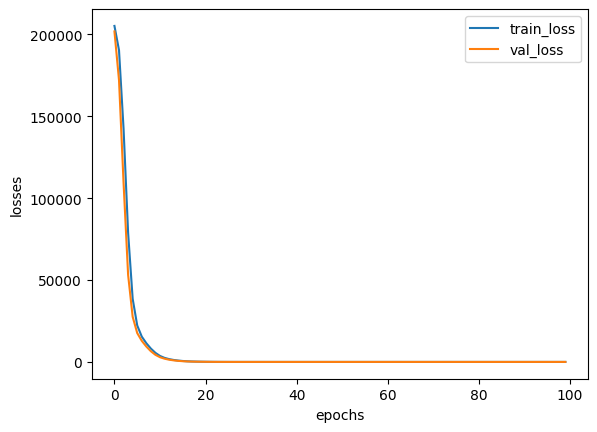

In [ ]:
import matplotlib.pyplot as plt # to plot val_loss and train_loss
loss_df=pd.DataFrame({
    "train_loss":train_losses,
    "val_loss":val_losses
}
)
plt.plot(loss_df["train_loss"],label="train_loss")
plt.plot(loss_df["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("losses")
plt.legend()


In [ ]:
# loading saved model and save them into architecture
model.load_state_dict(torch.load("best_model.pt"))


<All keys matched successfully>

In [ ]:
# evaluate our model
model.eval()
with torch.no_grad():
  train_pred=model(X_train_tensor)
  test_pred=model(X_test_tensor)
  train_mse_loss=criteroen(train_pred,y_train_tensor)
  test_mse_loss=criteroen(test_pred,y_test_tensor)

print(f"train_mse_loss:{train_mse_loss.item()}")
print(f"test_mse_loss:{test_mse_loss.item()}")

train_mse_loss:20.469337463378906
test_mse_loss:18.705739974975586


In [ ]:
from sklearn.metrics import r2_score
print(f"r2_score:{r2_score(y_test,test_pred)}")

r2_score:0.9346282699033884


In [ ]:
pred_df=pd.DataFrame(test_pred.numpy(),columns=["pred_vals"])
actual_df=pd.DataFrame(y_test.values,columns=["act_val"])
pd.concat([pred_df,actual_df],axis=1)

,pred_vals,act_val
0,434.839386,433.27
1,436.642242,438.16
2,461.358246,458.42
3,476.405914,480.82
4,435.213776,441.41
...,...,...
1909,451.028656,456.70
1910,431.266479,438.04
1911,467.363739,467.80
1912,430.743378,437.14
